# Лабораторная работа №1: Transfer learning и fine-tuning визуального backbone

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
- Сравнить frozen, partial и full fine-tuning ResNet18.
- Построить confusion matrix и проверить corruption shift.


## Теоретическая часть

Предобученный backbone реализует отображение $f_\theta(x)=z$. Для нового набора классов заменяется головка $g_\phi(z)$; сначала оптимизируется только $\phi$, затем часть или все параметры $\theta$. Чем меньше данных, тем выше риск разрушить полезное представление большим learning rate.

![Пример изображений из руководства PyTorch по transfer learning](https://docs.pytorch.org/tutorials/_images/sphx_glr_transfer_learning_tutorial_001.png)

Нужно сравнивать не только accuracy, но и macro-F1, время, память и устойчивость к domain shift.


### Математическая постановка

Для многоклассовой задачи используется cross-entropy:
$$\mathcal L=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i).$$
Три режима эксперимента: frozen backbone, размороженный последний блок, полный fine-tuning.


### Материалы

- [PyTorch Transfer Learning Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [torchvision models](https://pytorch.org/vision/stable/models.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
2. Сравнить frozen, partial и full fine-tuning ResNet18.
3. Построить confusion matrix и проверить corruption shift.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** ResNet18, FP32/FP16, 32–224 px.
- **Ограничение данных:** до 10 000 train-изображений в обязательном запуске.
- **Fallback:** CPU/FAST_DEV_RUN на подвыборке.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    # локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})

{'device': 'mps', 'fast_dev_run': False, 'data_root': '/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Разделение CIFAR-10

*Вес: 1 балл.*

**Постановка.** Изоляция test необходима для оценки обобщения без подбора по тестовым меткам.

Выполните следующие действия:
1. Загрузите CIFAR-10 и разделите train на стратифицированные train и validation.
2. Подготовьте DataLoader с детерминированным test-преобразованием.

**Результат.** Непересекающиеся train, validation и test и загрузчики train_loader, val_loader, test_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import hashlib
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

N_TRAIN, N_VAL = (512, 256) if FAST_DEV_RUN else (10_000, 2_000)
N_TEST = 512 if FAST_DEV_RUN else 10_000
IMG_SIZE = 96 if FAST_DEV_RUN else 224   # CIFAR 32 px увеличиваю до входного размера ImageNet-моделей
BATCH = 64

raw_train = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)
raw_test = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True)
classes = raw_train.classes
y_train_all = np.array(raw_train.targets)

# Утечка через одинаковые картинки: считаю md5 сырых пикселей и выбрасываю из официального train
# все изображения, которые побайтно встречаются в test или повторяются внутри train.
def md5(arr):
    return hashlib.md5(arr.tobytes()).hexdigest()
test_hashes = {md5(x) for x in raw_test.data}
seen, clean_idx, dropped = set(), [], 0
for i, x in enumerate(raw_train.data):
    h = md5(x)
    if h in test_hashes or h in seen:
        dropped += 1
        continue
    seen.add(h); clean_idx.append(i)
clean_idx = np.array(clean_idx)

# стратифицированно беру N_TRAIN + N_VAL из train, официальный test не трогаю
sub_idx, _ = train_test_split(clean_idx, train_size=N_TRAIN + N_VAL, stratify=y_train_all[clean_idx], random_state=SEED)
train_idx, val_idx = train_test_split(sub_idx, test_size=N_VAL, stratify=y_train_all[sub_idx], random_state=SEED)
test_idx = np.arange(N_TEST)

train_tf = T.Compose([T.RandomCrop(32, padding=4, padding_mode="reflect"), T.RandomHorizontalFlip(), T.ToTensor()])
eval_tf = T.ToTensor()  # детерминированное преобразование для validation и test
train_set = Subset(torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=train_tf), train_idx)
val_set = Subset(torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=eval_tf), val_idx)
test_set = Subset(torchvision.datasets.CIFAR10(DATA_ROOT, train=False, transform=eval_tf), test_idx)

loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, generator=loader_gen, num_workers=0)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prepare(x):
    """Масштабирование 32→IMG_SIZE и нормализация ImageNet уже на устройстве (одинаково для всех выборок)."""
    x = F.interpolate(x.to(DEVICE), size=IMG_SIZE, mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

check(len(set(train_idx) & set(val_idx)) == 0, "train и validation не пересекаются по индексам")
check(not ({md5(raw_train.data[i]) for i in sub_idx} & test_hashes), "в train/validation нет побайтных копий test-изображений")
counts = {s: np.bincount(y, minlength=10).tolist() for s, y in
          [("train", y_train_all[train_idx]), ("val", y_train_all[val_idx]), ("test", np.array(raw_test.targets)[test_idx])]}
check(max(counts["train"]) - min(counts["train"]) <= 2 and max(counts["val"]) - min(counts["val"]) <= 2, "train и validation сбалансированы по классам")

config = {"seed": SEED, "fast_dev_run": FAST_DEV_RUN, "n_train": len(train_idx), "n_val": len(val_idx), "n_test": len(test_idx),
          "img_size": IMG_SIZE, "batch_size": BATCH, "dropped_duplicates": dropped, "device": DEVICE,
          "torch": torch.__version__, "torchvision": torchvision.__version__}
(ARTIFACTS / "split.json").write_text(json.dumps({"config": config, "class_counts": counts,
    "train_idx": train_idx.tolist(), "val_idx": val_idx.tolist(), "test_idx": test_idx.tolist()}))
print(config)
print("классы:", classes)
print("размеры выборок:", len(train_set), len(val_set), len(test_set), "| удалено дубликатов:", dropped)

✔ train и validation не пересекаются по индексам
✔ в train/validation нет побайтных копий test-изображений
✔ train и validation сбалансированы по классам
{'seed': 42, 'fast_dev_run': False, 'n_train': 10000, 'n_val': 2000, 'n_test': 10000, 'img_size': 224, 'batch_size': 64, 'dropped_duplicates': 0, 'device': 'mps', 'torch': '2.14.1', 'torchvision': '0.29.1'}
классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
размеры выборок: 10000 2000 10000 | удалено дубликатов: 0


### Backbone и функции обучения

*Вес: 1 балл.*

**Постановка.** Режимы заморозки изменяют множество обновляемых параметров. Сравнивать их можно лишь при одинаковой функции потерь.

Выполните следующие действия:
1. Создайте ResNet18 с новой десятиклассовой головой.
2. Определите функции обучения и вычисления accuracy, macro-F1, матрицы ошибок.

**Результат.** Функции build_model, train_epoch и evaluate.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def build_model(arch="resnet18", mode="full", num_classes=10):
    """mode: frozen — учится только голова; partial — голова + последний блок; full — все веса."""
    if arch == "resnet18":
        model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        head, last_block = model.fc, model.layer4
    elif arch == "efficientnet_b0":
        model = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        head, last_block = model.classifier, model.features[-2:]
    else:
        raise ValueError(arch)
    for p in model.parameters():
        p.requires_grad = mode == "full"
    if mode in ("frozen", "partial"):
        for p in head.parameters():
            p.requires_grad = True
    if mode == "partial":
        for p in last_block.parameters():
            p.requires_grad = True
    model.head_params = list(head.parameters())
    return model.to(DEVICE)

def count_params(model):
    return {"trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "total": sum(p.numel() for p in model.parameters())}

def set_train_mode(model):
    # у замороженных BatchNorm не обновляю running statistics
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def sync():
    if DEVICE == "mps": torch.mps.synchronize()
    elif DEVICE == "cuda": torch.cuda.synchronize()

def allocated_mb():
    if DEVICE == "mps": return torch.mps.current_allocated_memory() / 2**20
    if DEVICE == "cuda": return torch.cuda.memory_allocated() / 2**20
    return 0.0

def train_epoch(model, loader, optimizer, scheduler=None):
    set_train_mode(model)
    total, n, peak = 0.0, 0, 0.0
    for x, y in loader:
        x, y = prepare(x), y.to(DEVICE)
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if scheduler is not None: scheduler.step()
        peak = max(peak, allocated_mb())
        total += loss.item() * len(y); n += len(y)
    return total / n, peak

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.append(torch.softmax(model(prepare(x)), 1).cpu()); labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

def evaluate(model, loader):
    probs, y = predict(model, loader)
    pred = probs.argmax(1)
    return {"accuracy": float(accuracy_score(y, pred)), "macro_f1": float(f1_score(y, pred, average="macro")),
            "confusion_matrix": confusion_matrix(y, pred, labels=range(10)).tolist(), "pred": pred, "y": y, "probs": probs}

_m = build_model("resnet18", "frozen")
with torch.no_grad():
    _out = _m(prepare(next(iter(val_loader))[0][:4]))
check(tuple(_out.shape) == (4, 10), f"ResNet18 с новой головой выдаёт логиты формы {tuple(_out.shape)}")
del _m, _out

✔ ResNet18 с новой головой выдаёт логиты формы (4, 10)


### Режимы fine-tuning

*Вес: 1 балл.*

**Постановка.** Валидация определяет режим разморозки до первого обращения к test.

Выполните следующие действия:
1. Обучите frozen, partial и full при одинаковом числе эпох.
2. Сохраните веса и метрики validation; выберите режим по macro-F1.

**Результат.** Файлы resnet18_*.pt и metrics.json с измеренными validation-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
EPOCHS = 1 if FAST_DEV_RUN else 8
LR_HEAD, LR_BACKBONE = 1e-3, 1e-4  # новая голова учится быстрее, предобученные веса — в 10 раз медленнее

def fit(arch, mode, epochs=EPOCHS):
    """Обучение с возобновлением: состояние сохраняется после каждой эпохи в ckpt_*.pt."""
    name = f"{arch}_{mode}"
    final_path, ckpt_path = ARTIFACTS / f"{name}.pt", ARTIFACTS / f"ckpt_{name}.pt"
    torch.manual_seed(SEED); loader_gen.manual_seed(SEED)   # одинаковая инициализация головы и порядок батчей
    model = build_model(arch, mode)
    if final_path.exists():
        saved = torch.load(final_path, map_location=DEVICE)
        model.load_state_dict(saved["state_dict"])
        print(f"{name}: загружены готовые веса ({saved['meta']['epochs']} эпох)")
        return model, saved["meta"]
    head_ids = {id(p) for p in model.head_params}
    groups = [{"params": [p for p in model.parameters() if p.requires_grad and id(p) in head_ids], "lr": LR_HEAD},
              {"params": [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids], "lr": LR_BACKBONE}]
    optimizer = torch.optim.AdamW([g for g in groups if g["params"]], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(train_loader))
    state = {"epoch": 0, "history": [], "train_time_s": 0.0, "peak_mem_mb": 0.0}
    if ckpt_path.exists():
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
        state = ck["state"]
        print(f"{name}: продолжаю с эпохи {state['epoch']}")
    if DEVICE == "mps": torch.mps.empty_cache()
    for epoch in range(state["epoch"], epochs):
        sync(); t0 = time.time()
        loss, peak = train_epoch(model, train_loader, optimizer, scheduler)
        sync(); state["train_time_s"] += time.time() - t0
        state["peak_mem_mb"] = max(state["peak_mem_mb"], peak)
        val = evaluate(model, val_loader)
        state["history"].append({"epoch": epoch + 1, "train_loss": loss, "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"]})
        state["epoch"] = epoch + 1
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "state": state}, ckpt_path)
        print(f"{name} эпоха {epoch + 1}/{epochs}: loss={loss:.4f} val_acc={val['accuracy']:.4f} val_F1={val['macro_f1']:.4f} ({state['train_time_s']:.0f} c)")
    val = evaluate(model, val_loader)
    meta = {"arch": arch, "mode": mode, "epochs": epochs, "lr_head": LR_HEAD, "lr_backbone": LR_BACKBONE,
            "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"], "train_time_s": state["train_time_s"],
            "peak_mem_mb": state["peak_mem_mb"], **count_params(model), "history": state["history"]}
    torch.save({"state_dict": model.state_dict(), "meta": meta}, final_path)
    ckpt_path.unlink(missing_ok=True)
    return model, meta

MODES = ["frozen", "partial", "full"]
resnet_meta = {}
for mode in MODES:
    model, meta = fit("resnet18", mode)
    resnet_meta[mode] = meta
    del model
best_mode = max(MODES, key=lambda m: resnet_meta[m]["val_macro_f1"])
(ARTIFACTS / "metrics.json").write_text(json.dumps({"split": "validation", "modes": resnet_meta, "selected_mode": best_mode}, indent=2))
for m in MODES:
    r = resnet_meta[m]
    print(f"{m:8s} val_acc={r['val_accuracy']:.4f} val_macro_F1={r['val_macro_f1']:.4f} обучаемых={r['trainable']:,} время={r['train_time_s']:.0f} c")
print("режим, выбранный по validation macro-F1:", best_mode)

resnet18_frozen эпоха 1/8: loss=1.0636 val_acc=0.8025 val_F1=0.7998 (6 c)


resnet18_frozen эпоха 2/8: loss=0.6043 val_acc=0.8270 val_F1=0.8242 (13 c)


resnet18_frozen эпоха 3/8: loss=0.5254 val_acc=0.8375 val_F1=0.8369 (19 c)


resnet18_frozen эпоха 4/8: loss=0.4939 val_acc=0.8325 val_F1=0.8314 (25 c)


resnet18_frozen эпоха 5/8: loss=0.4651 val_acc=0.8430 val_F1=0.8422 (31 c)


...

resnet18_full эпоха 5/8: loss=0.0665 val_acc=0.9345 val_F1=0.9344 (101 c)


resnet18_full эпоха 6/8: loss=0.0411 val_acc=0.9365 val_F1=0.9364 (121 c)


resnet18_full эпоха 7/8: loss=0.0301 val_acc=0.9360 val_F1=0.9358 (141 c)


resnet18_full эпоха 8/8: loss=0.0279 val_acc=0.9370 val_F1=0.9369 (161 c)


frozen   val_acc=0.8435 val_macro_F1=0.8425 обучаемых=5,130 время=50 c
partial  val_acc=0.9180 val_macro_F1=0.9179 обучаемых=8,398,858 время=72 c
full     val_acc=0.9370 val_macro_F1=0.9369 обучаемых=11,181,642 время=161 c
режим, выбранный по validation macro-F1: full


### Альтернативная архитектура и отложенный тест

*Вес: 1 балл.*

**Постановка.** Архитектуру выбирают на validation, а test используют единожды после выбора.

Выполните следующие действия:
1. Обучите EfficientNet-B0 при том же бюджете.
2. Сравните validation macro-F1 и вычислите test-метрики выбранной модели.

**Результат.** backbone_comparison.json и test_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
@torch.no_grad()
def throughput(model, n_batches=10, bs=256):
    model.eval()
    x = prepare(torch.rand(bs, 3, 32, 32))
    model(x); sync()
    t0 = time.time()
    for _ in range(n_batches):
        model(x)
    sync()
    return n_batches * bs / (time.time() - t0)

effnet, effnet_meta = fit("efficientnet_b0", best_mode)
resnet_best, _ = fit("resnet18", best_mode)   # веса уже сохранены, просто загружаются
candidates = {"resnet18": (resnet_best, resnet_meta[best_mode]), "efficientnet_b0": (effnet, effnet_meta)}
comparison = {}
for arch, (model, meta) in candidates.items():
    comparison[arch] = {"mode": best_mode, "val_accuracy": meta["val_accuracy"], "val_macro_f1": meta["val_macro_f1"],
                        "train_time_s": meta["train_time_s"], "peak_mem_mb": meta["peak_mem_mb"],
                        "params_total": meta["total"], "params_trainable": meta["trainable"],
                        "inference_img_per_s": throughput(model)}
selected_arch = max(comparison, key=lambda a: comparison[a]["val_macro_f1"])
(ARTIFACTS / "backbone_comparison.json").write_text(json.dumps({"selection_split": "validation", "selected": selected_arch,
                                                                 "models": comparison}, indent=2))
best_model = candidates[selected_arch][0]

# test используется один раз — после выбора архитектуры и режима по validation
test_eval = evaluate(best_model, test_loader)
test_metrics = {"model": f"{selected_arch}_{best_mode}", "n_test": len(test_set), "accuracy": test_eval["accuracy"],
                "macro_f1": test_eval["macro_f1"], "confusion_matrix": test_eval["confusion_matrix"]}
(ARTIFACTS / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))
import pandas as pd
print(pd.DataFrame(comparison).T.round(4))
print(f"выбрана модель {selected_arch} ({best_mode}); test accuracy={test_eval['accuracy']:.4f}, macro-F1={test_eval['macro_f1']:.4f}")

efficientnet_b0_full эпоха 1/8: loss=0.8188 val_acc=0.9070 val_F1=0.9068 (44 c)


efficientnet_b0_full эпоха 2/8: loss=0.2951 val_acc=0.9260 val_F1=0.9259 (86 c)


efficientnet_b0_full эпоха 3/8: loss=0.1990 val_acc=0.9385 val_F1=0.9385 (127 c)


efficientnet_b0_full эпоха 4/8: loss=0.1476 val_acc=0.9390 val_F1=0.9391 (169 c)


efficientnet_b0_full эпоха 5/8: loss=0.1184 val_acc=0.9435 val_F1=0.9436 (211 c)


efficientnet_b0_full эпоха 6/8: loss=0.1003 val_acc=0.9430 val_F1=0.9431 (253 c)


efficientnet_b0_full эпоха 7/8: loss=0.0867 val_acc=0.9430 val_F1=0.9429 (295 c)


efficientnet_b0_full эпоха 8/8: loss=0.0782 val_acc=0.9450 val_F1=0.9450 (337 c)


resnet18_full: загружены готовые веса (8 эпох)


                 mode val_accuracy val_macro_f1 train_time_s peak_mem_mb  \
resnet18         full        0.937     0.936865   161.420195  212.914795   
efficientnet_b0  full        0.945     0.944987    337.23745   102.55957   

                params_total params_trainable inference_img_per_s  
resnet18            11181642         11181642         1944.597562  
efficientnet_b0      4020358          4020358         1046.382072  
выбрана модель efficientnet_b0 (full); test accuracy=0.9435, macro-F1=0.9434


### Шумовой сдвиг и ошибки классификации

*Вес: 1 балл.*

**Постановка.** Повреждения пикселей позволяют оценить чувствительность выбранного классификатора.

Выполните следующие действия:
1. Примените шум к отложенным изображениям и измерьте accuracy.
2. Сохраните индексы фактических ошибочных предсказаний.

**Результат.** shift_metrics.json и errors.json с предсказаниями модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{'model': 'efficientnet_b0_full', 'noise': 'gaussian, pixel space [0,1], clamp', 'sigma': 0.1, 'n': 10000, 'clean_accuracy': 0.9435, 'noisy_accuracy': 0.3041}
ошибок на чистом test: 565 | на зашумлённом: 6959


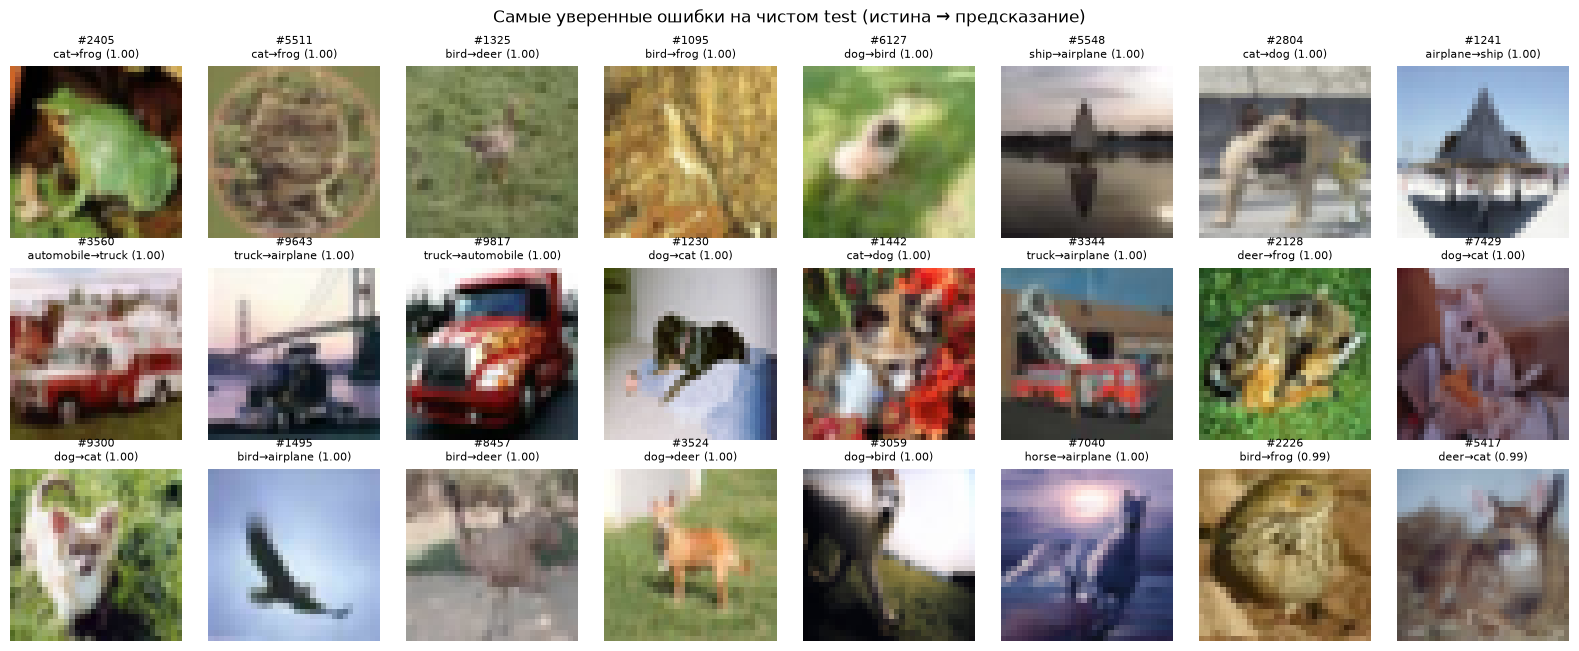

частые пары ошибок:
 cat→dog             78
dog→cat             47
truck→automobile    24
airplane→ship       23
automobile→truck    22
bird→deer           19
cat→frog            16
deer→cat            14


In [7]:
import matplotlib.pyplot as plt

X_test = torch.stack([test_set[i][0] for i in range(len(test_set))])   # [N,3,32,32] в [0,1]
y_test = np.array([raw_test.targets[i] for i in test_idx])
noise_base = torch.randn(X_test.shape, generator=torch.Generator().manual_seed(SEED))  # один шум для всех σ

@torch.no_grad()
def predict_tensor(model, X, bs=256):
    model.eval()
    return torch.cat([torch.softmax(model(prepare(X[i:i + bs])), 1).cpu() for i in range(0, len(X), bs)]).numpy()

def add_noise(X, sigma):
    return (X + sigma * noise_base).clamp(0, 1)

SIGMA = 0.1
clean_probs = predict_tensor(best_model, X_test)
clean_pred = clean_probs.argmax(1)
noisy_probs = predict_tensor(best_model, add_noise(X_test, SIGMA))
noisy_pred = noisy_probs.argmax(1)
shift = {"model": test_metrics["model"], "noise": "gaussian, pixel space [0,1], clamp", "sigma": SIGMA, "n": len(y_test),
         "clean_accuracy": float((clean_pred == y_test).mean()), "noisy_accuracy": float((noisy_pred == y_test).mean())}
(ARTIFACTS / "shift_metrics.json").write_text(json.dumps(shift, indent=2))

def error_list(pred, probs):
    wrong = np.where(pred != y_test)[0]
    return [{"test_index": int(test_idx[i]), "true": classes[y_test[i]], "pred": classes[pred[i]],
             "confidence": round(float(probs[i].max()), 4)} for i in wrong]
errors = {"clean": error_list(clean_pred, clean_probs), "noisy_sigma_%.2f" % SIGMA: error_list(noisy_pred, noisy_probs)}
(ARTIFACTS / "errors.json").write_text(json.dumps(errors, indent=1, ensure_ascii=False))
print(shift)
print("ошибок на чистом test:", len(errors["clean"]), "| на зашумлённом:", len(errors["noisy_sigma_%.2f" % SIGMA]))

# 24 самые уверенные ошибки на чистом test — для ручного разбора
conf_err = sorted(errors["clean"], key=lambda e: -e["confidence"])[:24]
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))
for ax, e in zip(axes.flat, conf_err):
    ax.imshow(raw_test.data[e["test_index"]]); ax.axis("off")
    ax.set_title(f"#{e['test_index']}\n{e['true']}→{e['pred']} ({e['confidence']:.2f})", fontsize=8)
fig.suptitle("Самые уверенные ошибки на чистом test (истина → предсказание)")
fig.tight_layout(); fig.savefig(ARTIFACTS / "errors_examples.png", dpi=110); plt.show()
pairs = pd.Series([f"{e['true']}→{e['pred']}" for e in errors["clean"]]).value_counts().head(8)
print("частые пары ошибок:\n", pairs.to_string())

### Профиль устойчивости к шуму

*Вес: 1 балл.*

**Постановка.** Одна интенсивность повреждения не описывает характер деградации.

Выполните следующие действия:
1. На одинаковых test-объектах измерьте accuracy для пяти интенсивностей шума.
2. Сохраните профиль деградации.

**Результат.** sigma_sensitivity.json с измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


✔ точность не растёт при усилении шума
σ=0.00: accuracy=0.9435
σ=0.02: accuracy=0.9032
σ=0.05: accuracy=0.6878
σ=0.10: accuracy=0.3041
σ=0.20: accuracy=0.1731
σ=0.30: accuracy=0.1253


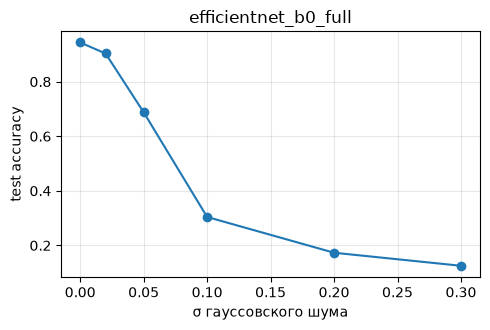

In [8]:
SIGMAS = [0.02, 0.05, 0.1, 0.2, 0.3]
profile = [{"sigma": 0.0, "accuracy": float((clean_pred == y_test).mean())}]
for s in SIGMAS:
    pred_s = predict_tensor(best_model, add_noise(X_test, s)).argmax(1)
    profile.append({"sigma": s, "accuracy": float((pred_s == y_test).mean())})
(ARTIFACTS / "sigma_sensitivity.json").write_text(json.dumps({"model": test_metrics["model"], "n": len(y_test), "profile": profile}, indent=2))
check(all(a["accuracy"] >= b["accuracy"] - 0.01 for a, b in zip(profile, profile[1:])), "точность не растёт при усилении шума")
for p in profile: print(f"σ={p['sigma']:.2f}: accuracy={p['accuracy']:.4f}")
plt.figure(figsize=(5, 3.4))
plt.plot([p["sigma"] for p in profile], [p["accuracy"] for p in profile], "o-")
plt.xlabel("σ гауссовского шума"); plt.ylabel("test accuracy"); plt.title(test_metrics["model"]); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(ARTIFACTS / "sigma_sensitivity.png", dpi=110); plt.show()

### Доля обучаемых параметров

*Вес: 1 балл.*

**Постановка.** Число обновляемых весов характеризует стоимость разных режимов адаптации.

Выполните следующие действия:
1. Посчитайте параметры каждого режима разморозки.
2. Проверьте порядок frozen, partial, full.

**Результат.** param_report.json с числами параметров трёх моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
param_report = {}
for mode in MODES:
    m = build_model("resnet18", mode)
    c = count_params(m)
    param_report[mode] = {**c, "fraction": c["trainable"] / c["total"]}
    del m
(ARTIFACTS / "param_report.json").write_text(json.dumps(param_report, indent=2))
check(param_report["frozen"]["trainable"] < param_report["partial"]["trainable"] < param_report["full"]["trainable"],
      "число обучаемых параметров растёт: frozen < partial < full")
for k, v in param_report.items(): print(f"{k:8s} {v['trainable']:>12,} из {v['total']:,} ({v['fraction']:.2%})")

✔ число обучаемых параметров растёт: frozen < partial < full
frozen          5,130 из 11,181,642 (0.05%)
partial     8,398,858 из 11,181,642 (75.11%)
full       11,181,642 из 11,181,642 (100.00%)


### Поклассовые ошибки

*Вес: 1 балл.*

**Постановка.** Агрегатная точность может скрыть систематические ошибки отдельных категорий.

Выполните следующие действия:
1. Вычислите recall для каждого класса по test confusion matrix.
2. Найдите класс с наименьшим recall.

**Результат.** class_report.json с поклассовым recall и худшим классом.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
 "model": "efficientnet_b0_full",
 "recall": {
  "airplane": 0.95,
  "automobile": 0.969,
  "bird": 0.934,
  "cat": 0.859,
  "deer": 0.932,
  "dog": 0.923,
  "frog": 0.97,
  "horse": 0.961,
  "ship": 0.976,
  "truck": 0.961
 },
 "worst_class": "cat",
 "worst_recall": 0.859,
 "most_confused_with": "dog"
}


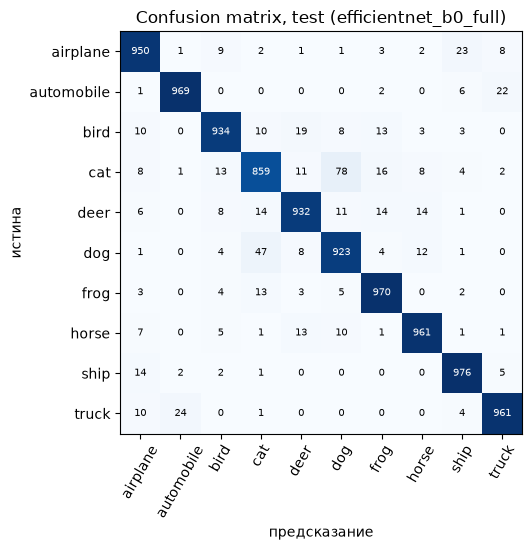

In [10]:
cm = np.array(test_metrics["confusion_matrix"])
recall = cm.diagonal() / cm.sum(1)
worst = int(recall.argmin())
class_report = {"model": test_metrics["model"], "recall": {classes[i]: float(recall[i]) for i in range(10)},
                "worst_class": classes[worst], "worst_recall": float(recall[worst]),
                "most_confused_with": classes[int(np.argsort(cm[worst])[-2])]}
(ARTIFACTS / "class_report.json").write_text(json.dumps(class_report, indent=2))
print(json.dumps(class_report, indent=1))
fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), classes, rotation=60); ax.set_yticks(range(10), classes)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("предсказание"); ax.set_ylabel("истина"); ax.set_title(f"Confusion matrix, test ({test_metrics['model']})")
fig.tight_layout(); fig.savefig(ARTIFACTS / "confusion_matrix.png", dpi=110); plt.show()

### Точность и стоимость обучения

*Вес: 1 балл.*

**Постановка.** Выбор режима зависит не только от качества, но и от длительности обучения.

Выполните следующие действия:
1. Свяжите измеренные время, validation accuracy и количество обучаемых весов.
2. Сохраните сопоставимую таблицу режимов.

**Результат.** efficiency_report.json с наблюдаемыми величинами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
efficiency = {}
for mode in MODES:
    r = resnet_meta[mode]
    m, _ = fit("resnet18", mode)
    efficiency[mode] = {"train_time_s": r["train_time_s"], "time_per_epoch_s": r["train_time_s"] / r["epochs"],
                        "val_accuracy": r["val_accuracy"], "val_macro_f1": r["val_macro_f1"],
                        "trainable_params": r["trainable"], "peak_mem_mb_sampled": r["peak_mem_mb"],
                        "inference_img_per_s": throughput(m)}
    del m
efficiency["efficientnet_b0_" + best_mode] = {"train_time_s": effnet_meta["train_time_s"], "time_per_epoch_s": effnet_meta["train_time_s"] / effnet_meta["epochs"],
                                              "val_accuracy": effnet_meta["val_accuracy"], "val_macro_f1": effnet_meta["val_macro_f1"],
                                              "trainable_params": effnet_meta["trainable"], "peak_mem_mb_sampled": effnet_meta["peak_mem_mb"],
                                              "inference_img_per_s": comparison["efficientnet_b0"]["inference_img_per_s"]}
(ARTIFACTS / "efficiency_report.json").write_text(json.dumps({"device": DEVICE, "epochs": EPOCHS, "n_train": len(train_set),
                                                               "img_size": IMG_SIZE, "rows": efficiency}, indent=2))
print(pd.DataFrame(efficiency).T.round(3).to_string())

resnet18_frozen: загружены готовые веса (8 эпох)


resnet18_partial: загружены готовые веса (8 эпох)


resnet18_full: загружены готовые веса (8 эпох)


                      train_time_s  time_per_epoch_s  val_accuracy  val_macro_f1  trainable_params  peak_mem_mb_sampled  inference_img_per_s
frozen                      49.957             6.245         0.844         0.843            5130.0               79.758             1936.495
partial                     71.762             8.970         0.918         0.918         8398858.0              176.574             1935.612
full                       161.420            20.178         0.937         0.937        11181642.0              212.915             1936.651
efficientnet_b0_full       337.237            42.155         0.945         0.945         4020358.0              102.560             1046.382


### Анализ ошибок при максимальном сдвиге

*Вес: 1 балл.*

**Постановка.** Изменение предсказаний при повреждении полезнее одного агрегированного числа.

Выполните следующие действия:
1. Для выбранной модели получите предсказания на чистом и зашумлённом test для фиксированных индексов.
2. Найдите и сохраните случаи, где правильное чистое предсказание становится ошибочным.

**Результат.** shift_failures.json с индексами и предсказаниями на реальных изображениях.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


σ=0.3: 8241 из 9435 верных предсказаний стали ошибочными
во что превращаются предсказания под шумом:
 airplane    4705
bird        2205
frog         858
ship         305
cat          155


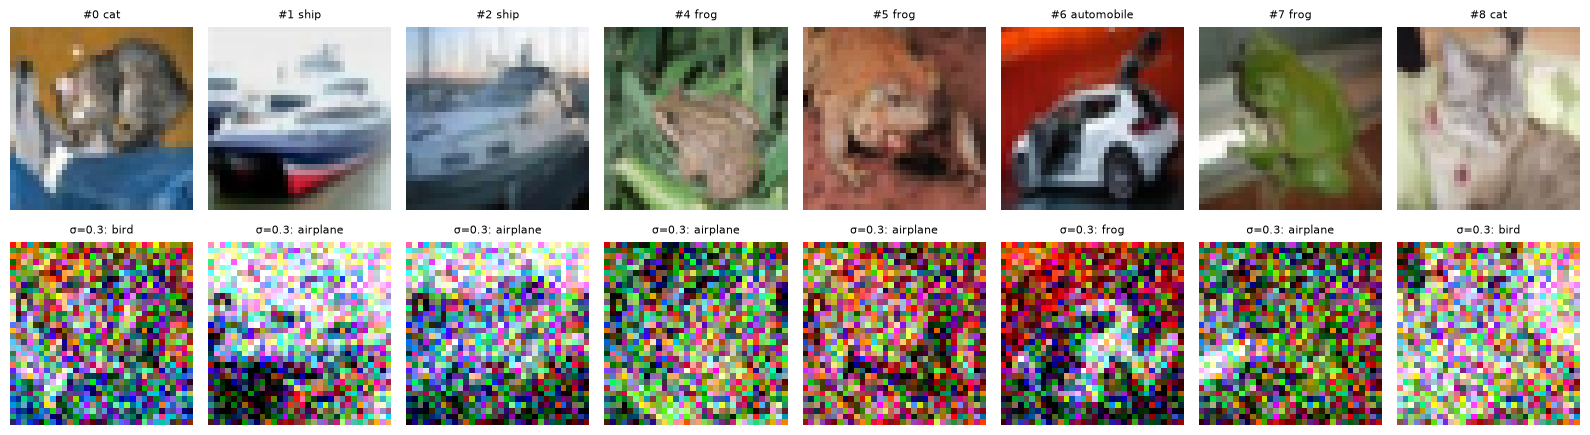

In [12]:
SIGMA_MAX = max(SIGMAS)
max_probs = predict_tensor(best_model, add_noise(X_test, SIGMA_MAX))
max_pred = max_probs.argmax(1)
flip_idx = np.where((clean_pred == y_test) & (max_pred != y_test))[0]
failures = [{"test_index": int(test_idx[i]), "true": classes[y_test[i]], "clean_pred": classes[clean_pred[i]],
             "noisy_pred": classes[max_pred[i]], "noisy_confidence": round(float(max_probs[i].max()), 4)} for i in flip_idx]
by_target = pd.Series([f["noisy_pred"] for f in failures]).value_counts()
(ARTIFACTS / "shift_failures.json").write_text(json.dumps({"model": test_metrics["model"], "sigma": SIGMA_MAX,
    "n_fixed_indices": len(y_test), "n_clean_correct": int((clean_pred == y_test).sum()), "n_broken_by_noise": len(failures),
    "noisy_prediction_counts": by_target.to_dict(), "cases": failures}, ensure_ascii=False))
print(f"σ={SIGMA_MAX}: {len(failures)} из {(clean_pred == y_test).sum()} верных предсказаний стали ошибочными")
print("во что превращаются предсказания под шумом:\n", by_target.head(5).to_string())
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for k, i in enumerate(flip_idx[:8]):
    axes[0, k].imshow(X_test[i].permute(1, 2, 0)); axes[0, k].set_title(f"#{test_idx[i]} {classes[clean_pred[i]]}", fontsize=8)
    axes[1, k].imshow(add_noise(X_test[i:i + 1], SIGMA_MAX)[0].permute(1, 2, 0)); axes[1, k].set_title(f"σ={SIGMA_MAX}: {classes[max_pred[i]]}", fontsize=8)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "shift_failures.png", dpi=110); plt.show()

### Творческий бонус: новый тип сдвига

*Вес: 1 дополнительный балл.*

**Постановка.** Не все повреждения изображений похожи на гауссовский шум.

Выполните следующие действия:
1. Выберите воспроизводимое фотометрическое или геометрическое преобразование test-изображений.
2. Сравните точность с чистым test и приведите три конкретных примера изменения предсказания.

**Результат.** bonus_shift.json с описанием преобразования, метрикой и индексами примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
 "transform": "torchvision adjust_brightness(factor=0.35)",
 "model": "efficientnet_b0_full",
 "n": 10000,
 "clean_accuracy": 0.9435,
 "shifted_accuracy": 0.8789,
 "n_broken": 832,
 "examples": [
  {
   "test_index": 26,
   "true": "deer",
   "clean_pred": "deer",
   "dark_pred": "cat",
   "dark_confidence": 0.9044
  },
  {
   "test_index": 68,
   "true": "cat",
   "clean_pred": "cat",
   "dark_pred": "deer",
   "dark_confidence": 0.5487
  },
  {
   "test_index": 69,
   "true": "horse",
   "clean_pred": "horse",
   "dark_pred": "deer",
   "dark_confidence": 0.9226
  }
 ]
}


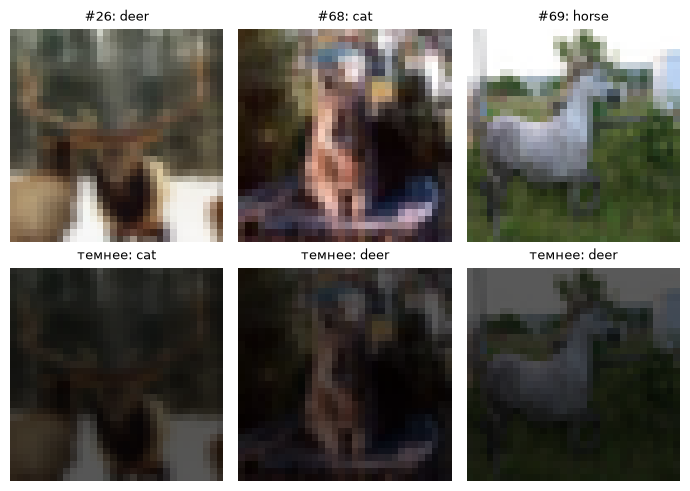

In [13]:
import torchvision.transforms.functional as TF
BRIGHTNESS = 0.35   # имитация съёмки при слабом освещении: яркость ×0.35, без случайности
X_dark = TF.adjust_brightness(X_test, BRIGHTNESS)
dark_probs = predict_tensor(best_model, X_dark)
dark_pred = dark_probs.argmax(1)
changed = np.where((clean_pred == y_test) & (dark_pred != y_test))[0]
examples = [{"test_index": int(test_idx[i]), "true": classes[y_test[i]], "clean_pred": classes[clean_pred[i]],
             "dark_pred": classes[dark_pred[i]], "dark_confidence": round(float(dark_probs[i].max()), 4)} for i in changed[:3]]
bonus = {"transform": f"torchvision adjust_brightness(factor={BRIGHTNESS})", "model": test_metrics["model"], "n": len(y_test),
         "clean_accuracy": float((clean_pred == y_test).mean()), "shifted_accuracy": float((dark_pred == y_test).mean()),
         "n_broken": int(len(changed)), "examples": examples}
(ARTIFACTS / "bonus_shift.json").write_text(json.dumps(bonus, indent=2, ensure_ascii=False))
print(json.dumps(bonus, indent=1, ensure_ascii=False))
fig, axes = plt.subplots(2, 3, figsize=(7, 5))
for k, e in enumerate(examples):
    i = int(np.where(test_idx == e["test_index"])[0][0])
    axes[0, k].imshow(X_test[i].permute(1, 2, 0)); axes[0, k].set_title(f"#{e['test_index']}: {e['clean_pred']}", fontsize=9)
    axes[1, k].imshow(X_dark[i].permute(1, 2, 0)); axes[1, k].set_title(f"темнее: {e['dark_pred']}", fontsize=9)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "bonus_shift.png", dpi=110); plt.show()

## Анализ результатов

**Бюджет.** 10 000 train и 2 000 validation (стратифицированно из официального train, без побайтных копий test-изображений), официальный test — 10 000. Вход 224 px (CIFAR 32 px увеличивается билинейно), 8 эпох, batch 64, AdamW: голова 1e-3, предобученные веса 1e-4, cosine schedule. Всё считалось на MacBook Pro M3 Max через PyTorch MPS в FP32: autocast на MPS в предварительном замере не дал ускорения.

**Режимы ResNet18 (validation):**

| режим | обучаемых параметров | val accuracy | val macro-F1 | время обучения | с/эпоху |
|---|---:|---:|---:|---:|---:|
| frozen | 5 130 (0,05 %) | 0,844 | 0,843 | 50 с | 6,2 |
| partial (layer4 + голова) | 8,4 M (75 %) | 0,918 | 0,918 | 72 с | 9,0 |
| full | 11,2 M (100 %) | 0,937 | 0,937 | 161 с | 20,2 |

Одной головы мало: признаки ImageNet для увеличенных 32-px картинок линейно разделяются только на 84 %. Разморозка последнего блока даёт +7,5 п. п. за 45 % времени полного обучения, full — ещё +1,9 п. п.

**ResNet18 и EfficientNet-B0 (full, одинаковый бюджет):** EfficientNet-B0 точнее (val macro-F1 0,945 против 0,937) при в 2,8 раза меньшем числе параметров, но учится в 2,1 раза дольше (337 с против 161 с) и в инференсе вдвое медленнее (1 046 против 1 945 изобр./с): depthwise-свёртки плохо загружают GPU Apple. Пиковая выделенная память по замерам на шагах — 103 МБ против 213 МБ. По validation выбрана EfficientNet-B0.

**Test (обращение одно, после выбора):** accuracy 0,9435, macro-F1 0,9434. Хуже всего распознаётся cat (recall 0,859), чаще всего путается с dog. Из 565 ошибок 125 приходятся на пару cat↔dog, 46 на truck↔automobile, 23 на airplane→ship.

**24 самые уверенные ошибки** (`errors_examples.png`). Примерно треть из них — спорная или ошибочная разметка самого CIFAR-10: #2405 — лягушка с меткой cat, #2804 — мопс с меткой cat, #9643 — вертолёт с меткой truck, #7429 — кошка с меткой dog. Пожарные машины и фургоны (#3560, #9817, #3344) находятся на границе automobile/truck. В #7040 (horse→airplane) и #1495 (bird→airplane) фон-небо перевешивает силуэт.

**Гауссовский шум** (одна и та же реализация шума на всех 10 000 test-изображениях): accuracy 0,944 → 0,903 (σ=0,02) → 0,688 (0,05) → 0,304 (0,1) → 0,173 (0,2) → 0,125 (0,3). Шум добавляется к исходным 32×32 пикселям и вместе с картинкой увеличивается в 7 раз, поэтому для сети это крупные цветные пятна, которых не было ни в ImageNet, ни в обучении. При σ=0,3 ломаются 8 241 из 9 435 верных предсказаний, и почти все уходят в airplane (4 705) и bird (2 205): модель вырождается в классы с однородным фоном.

**Бонус — затемнение (яркость ×0,35):** accuracy 0,879 (−6,5 п. п.). Фотометрический сдвиг переносится заметно лучше шума; ломаются в основном животные (deer→cat, horse→deer).

**Ограничения:** одно разбиение и один seed; 8 эпох без подбора гиперпараметров для каждого режима; время на MPS нельзя напрямую сравнивать с CUDA. Запуск `FAST_DEV_RUN=True` (512 изображений, 1 эпоха, 96 px) использовался только для проверки кода и в выводах не участвует.

## Выводы

1. При 10 тыс. размеченных изображений полный fine-tuning предобученной сети выигрывает у frozen-режима 9 п. п.; partial даёт около 80 % этого выигрыша меньше чем за половину времени.
2. EfficientNet-B0 точнее ResNet18 при меньшем числе параметров, но на MPS вдвое медленнее и в обучении, и в инференсе. Выбор зависит от того, что важнее: качество или задержка.
3. Модель не устойчива к пиксельному шуму: уже σ=0,05 стоит 26 п. п. accuracy. Нужна аугментация шумом или размытием либо обучение на corruptions. Затемнение модель переносит гораздо лучше.
4. Заметная часть «ошибок» — шум разметки CIFAR-10, поэтому разница между моделями в десятые доли процента статистически ненадёжна.